In [55]:
import numpy as np
import json
from matplotlib import pyplot as plt

In [182]:
names_to_capital = {
    "hinge":"Hinge",
    "log": "Logistic",
    "log_loss": "Logistic",
    "modified_huber": "Modified Huber",
    "squared_hinge": "Squared hinge",
    "perceptron": "Perception",
    "gbdt": "GBDT"
}

In [173]:
neg_pos_ratio_dict = {
    "is_rct": 5585042/489295,
    "is_sr": 5659292/121063,
    "is_casecontrol": 5628219/65790,
    "is_cohort": 5632460/78688,
    "is_guideline": 5676411/33826
}

ptype2pos = {
    "is_rct": 0,
    "is_sr": 1,
    "is_casecontrol": 2,
    "is_cohort": 3,
    "is_guideline": 4
}

In [174]:
def calc_precision(recall, specificity, neg_pos_ratio):
    return recall / (recall + neg_pos_ratio * (1 - specificity) + 1e-15)

def calc_f1(recall, precision):
    return 2*recall*precision/(recall+precision + 1e-15)

In [175]:
# study_design = ["RCT", "SR", "CCS", "CS", "G"]
# f1_scores = {
#     "Hinge": [0.44, 0.69, 0.058, 0.058, 0.13],
#     "Logistic": [0.47, 0.72, 0.059, 0.058, 0.13],
#     "Modified Huber": [0.46, 0.64, 0.048, 0.053, 0.093],
#     "Squared hinge": [0.40, 0.57, 0.053, 0.053, 0.13],
#     "Perception": [0.43, 0.65, 0.047, 0.053, 0.11],
#     "GBDT": [0.48, 0.74, 0.048, 0.057, 0.12]
# }

In [176]:
with open("results_titles_abstracts_linear_features1000.json") as f:
    linear_results_features1000 = json.load(f)

In [179]:
linear_results_features1000[0]

{'ptype': 'is_rct',
 'model_type': 'hinge',
 'neg_to_pos_ratio': 1,
 'best_penalty': 'l1',
 'best_alpha': 0.00029211869802209776,
 'recall_val': 0.831,
 'spec_val': 0.84925,
 'precision_val_even': 0.8464476699770818,
 'f1_val_even': 0.8386527059417181,
 'accuracy_val': 0.840125,
 'recall_test': 0.8265,
 'spec_test': 0.85375,
 'precision_test_even': 0.8496530454895914,
 'f1_test_even': 0.8379166138638957,
 'accuracy_test': 0.840125}

In [180]:
results_f1 = {}
for results in linear_results_features1000:
    ptype = results['ptype']
    if ptype not in results_f1:
        results_f1[ptype] = {}
    model_type = results['model_type']
    spec = results['spec_test']
    recall = results['recall_test']
    
    precision = calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype])
    
    results_f1[ptype][model_type] = calc_f1(recall, precision)

In [184]:
with open("results_titles_abstracts_gbdt_features1000.json") as f:
    gbdt_results_features1000 = json.load(f)

In [185]:
for results in gbdt_results_features1000:
    ptype = results['ptype']
    if ptype not in results_f1:
        results_f1[ptype] = {}
    model_type = results['model_type']
    spec = results['spec_test']
    recall = results['recall_test']
    
    precision = calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype])
    
    results_f1[ptype][model_type] = calc_f1(recall, precision)

In [186]:
results_f1

{'is_rct': {'hinge': 0.4728442231409485,
  'log_loss': 0.47042392555644164,
  'modified_huber': 0.48593507284402737,
  'squared_hinge': 0.48237506650439155,
  'perceptron': 0.3435705021524647,
  'gbdt': 0.4950534079208214},
 'is_sr': {'hinge': 0.5543919862860253,
  'log_loss': 0.5324625394982972,
  'modified_huber': 0.5942153984377058,
  'squared_hinge': 0.5816400816822432,
  'perceptron': 0.3780418996025804,
  'gbdt': 0.6481989571792441},
 'is_casecontrol': {'hinge': 0.08851842661692318,
  'log_loss': 0.08691174337916423,
  'modified_huber': 0.09109927112425541,
  'squared_hinge': 0.08878839921322566,
  'perceptron': 0.0578743756725752,
  'gbdt': 0.08886737046729357},
 'is_cohort': {'hinge': 0.09778065048695563,
  'log_loss': 0.10122559720751582,
  'modified_huber': 0.09969583825523255,
  'squared_hinge': 0.07708373527083578,
  'perceptron': 0.06741529894108254,
  'gbdt': 0.10293184168552673},
 'is_guideline': {'hinge': 0.10148058440955053,
  'log_loss': 0.10286718807324777,
  'modifi

In [187]:
study_design = ["RCT", "SR", "CCS", "CS", "G"]
f1_scores = {
    "Hinge": [0]*5,
    "Logistic": [0]*5,
    "Modified Huber": [0]*5,
    "Squared hinge": [0]*5,
    "Perception": [0]*5,
    "GBDT": [0]*5
}

In [188]:
for ptype in results_f1:
    pos = int(ptype2pos[ptype])
    for model_type in results_f1[ptype]:
        capital_name = names_to_capital[model_type]
        f1_scores[capital_name][pos] = results_f1[ptype][model_type]

In [191]:
with open("results_crossval_linear_features1000.json") as f:
    cross_val_linear_results = json.load(f)

In [192]:
with open("results_crossval_gbdt_features1000.json") as f:
    cross_val_gbdt_results = json.load(f)

In [193]:
# uncertainty = {
#     "Hinge": [0.025610718, 0.023481231, 0.004481872, 0.004014799, 0.018101314],
#     "Logistic": [0.027584642, 0.023153417, 0.004657664, 0.003896586, 0.017579469],
#     "Modified Huber": [0.027695767, 0.023682141, 0.003344116, 0.003393667, 0.011085227],
#     "Squared hinge": [0.022529108, 0.023097297, 0.004001562, 0.003403496, 0.017388526],
#     "Perception": [0.025356512, 0.070809891, 0.003221971, 0.003442154, 0.01525655],
#     "GBDT": [0.028133503, 0.074370221, 0.003195677, 0.003787735, 0.016768755]
# }

In [194]:
cross_val_f1 = {}
for cross_val_result in cross_val_linear_results:
    ptype = cross_val_result['ptype']
    if ptype not in cross_val_f1:
        cross_val_f1[ptype] = {}
    model_type = cross_val_result['model_type']
    
    spec_lst = cross_val_result['scores']['test_spec']
    recall_lst = cross_val_result['scores']['test_recall']
    prec_lst = []
    for recall, spec in zip(recall_lst, spec_lst):
        prec_lst.append(calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype]))
        
    f1_lst = [calc_f1(recall, precision) for recall, precision in zip(recall_lst, prec_lst)]
    cross_val_f1[ptype][model_type] = f1_lst

In [195]:
for cross_val_result in cross_val_gbdt_results:
    ptype = cross_val_result['ptype']
    if ptype not in cross_val_f1:
        cross_val_f1[ptype] = {}
    model_type = cross_val_result['model_type']
    
    spec_lst = cross_val_result['scores']['test_spec']
    recall_lst = cross_val_result['scores']['test_recall']
    prec_lst = []
    for recall, spec in zip(recall_lst, spec_lst):
        prec_lst.append(calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype]))
        
    f1_lst = [calc_f1(recall, precision) for recall, precision in zip(recall_lst, prec_lst)]
    cross_val_f1[ptype][model_type] = f1_lst

In [196]:
uncertainty = {
    "Hinge": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "Logistic": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "Modified Huber": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "Squared hinge": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "Perception": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "GBDT": {
        "upper": [0]*5,
        "lower": [0]*5
    }
}

In [197]:
for ptype in cross_val_f1:
    pos = int(ptype2pos[ptype])
    for model_type in cross_val_f1[ptype]:
        capital_name = names_to_capital[model_type]
        f1_lst = cross_val_f1[ptype][model_type]
        uquartile = np.quantile(f1_lst, 0.75)
        median = np.quantile(f1_lst, 0.5)
        lquartile = np.quantile(f1_lst, 0.25)
        uncertainty[capital_name]['upper'][pos] = uquartile - median
        uncertainty[capital_name]['lower'][pos] = median - lquartile

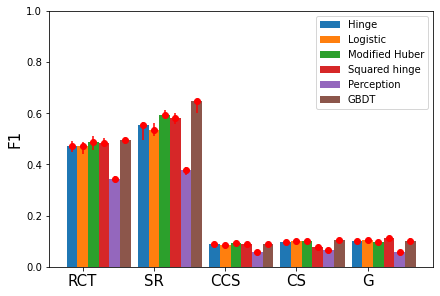

In [198]:
x = np.arange(len(study_design))  # the label locations
width = 0.15  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')


for attribute, measurement in f1_scores.items():
    offset = width * multiplier
    uquartile = np.array(uncertainty[attribute]['upper'])
    lquartile = np.array(uncertainty[attribute]['lower'])
    errors = [lquartile, uquartile]
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.errorbar(x + offset, measurement, yerr=errors, fmt="o", color="r")
#     ax.bar_label(rects, padding=5)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('F1', fontsize=15)
# ax.set_title('Penguin attributes by species')
ax.set_xticks(x + width, study_design, fontsize=15)
ax.legend(loc='upper right')
ax.set_ylim(0, 1)

plt.show()

In [202]:
study_design = ["RCT", "SR", "CCS", "CS", "G"]
f1_scores = {
    "Distill-BERT": [0.426315052, 0.230561852, 0.044509131, 0.055189855, 0.200366005],
    "BERT": [0.478742668, 0.466274223, 0.031361957, 0.05162278, 0.099012706],
    "SciBERT": [0.449020785, 0.586594286, 0, 0.049343384, 0.134729002],
    "BioBERT": [0.496979226, 0.603463669, 0.060381179, 0.041859691, 0.113203231],
    "PubMedBERT": [0.498685778, 0.690462671, 0.061608134, 0.058381448, 0.165611477]
}

uncertainty = {
    "Distill-BERT": [0.023787965, 0.021691624, 0.002870593, 0.003847079, 0.033512934],
    "BERT": [0.028023104, 0.051506093, 0.001684881, 0.003323312, 0.012063577],
    "SciBERT": [0.024736343, 0.064788632, 0, 0.003071094, 0.018754726],
    "BioBERT": [0.028558737, 0.066468423, 0.004501907, 0.002356557, 0.014664682],
    "PubMedBERT": [0.027860858, 0.072651682, 0.004588776, 0.00393121, 0.025420095]
}

In [203]:
with open("results_crossval_bert.json") as f:
    cross_val_bert_results = json.load(f)

In [204]:
uncertainty = {
    "Distill-BERT": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "BERT": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "SciBERT": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "BioBERT": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "PubMedBERT": {
        "upper": [0]*5,
        "lower": [0]*5
    }
}

In [205]:
names_to_capital = {
    "distilbert-base-uncased": "Distill-BERT",
    "bert-base-cased": "BERT",
    "allenai/scibert_scivocab_uncased": "SciBERT",
    "dmis-lab/biobert-base-cased-v1.2": "BioBERT",
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext": "PubMedBERT"
}

In [206]:
cross_val_f1 = {}
for cross_val_result in cross_val_bert_results:
    ptype = cross_val_result['ptype']
    if ptype not in cross_val_f1:
        cross_val_f1[ptype] = {}
    model_type = cross_val_result['model_type']
    
    spec_lst = cross_val_result['score_dict']['spec_test']
    recall_lst = cross_val_result['score_dict']['recall_test']
    prec_lst = []
    for recall, spec in zip(recall_lst, spec_lst):
        prec_lst.append(calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype]))
        
    f1_lst = [calc_f1(recall, precision) for recall, precision in zip(recall_lst, prec_lst)]
    cross_val_f1[ptype][model_type] = f1_lst

In [207]:
for ptype in cross_val_f1:
    pos = int(ptype2pos[ptype])
    for model_type in cross_val_f1[ptype]:
        capital_name = names_to_capital[model_type]
        f1_lst = cross_val_f1[ptype][model_type]
        uquartile = np.quantile(f1_lst, 0.75)
        median = np.quantile(f1_lst, 0.5)
        lquartile = np.quantile(f1_lst, 0.25)
        uncertainty[capital_name]['upper'][pos] = uquartile - median
        uncertainty[capital_name]['lower'][pos] = median - lquartile

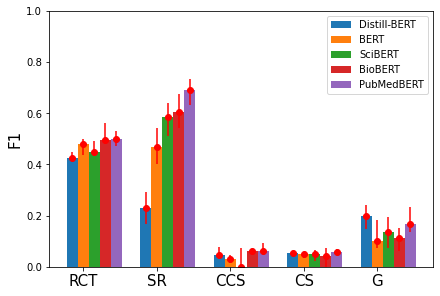

In [208]:
x = np.arange(len(study_design))  # the label locations
width = 0.15  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for attribute, measurement in f1_scores.items():
    offset = width * multiplier
    uquartile = np.array(uncertainty[attribute]['upper'])
    lquartile = np.array(uncertainty[attribute]['lower'])
    errors = [lquartile, uquartile]
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.errorbar(x + offset, measurement, yerr=errors, fmt="o", color="r")
#     ax.bar_label(rects, padding=5)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('F1', fontsize=15)
# ax.set_title('Penguin attributes by species')
ax.set_xticks(x + width, study_design, fontsize=15)
ax.legend(loc='upper right')
ax.set_ylim(0, 1)

plt.show()

In [227]:
with open("results_node2vec_gbdt_sample.json") as f:
    node2vec_gbdt_sample_results = json.load(f)

In [209]:
with open("results_titles_abstracts_gnn_bow.json") as f:
    gnn_bow_results_features1000 = json.load(f)

In [254]:
with open("results_bow_node2vec_concat_gbdt.json") as f:
    bow_node2vec_concat_gbdt_results = json.load(f)

In [255]:
with open("results_ensemble_text_node2vec_gbdt.json") as f:
    ensemble_text_node2vec_gbdt_results = json.load(f)

In [315]:
study_design = ["RCT", "SR", "CCS", "CS", "G"]
f1_scores = {
    "GAT": [0]*5,
    "GCN": [0]*5,
    "SAGENet": [0]*5,
    "node2vec": [0]*5,
    "node2vec_text_concat": [0]*5,
    "node2vec_text_ensemble_even": [0]*5,
#     "node2vec_text_ensemble_proportional": [0]*5,
#     "node2vec_text_ensemble_learnt": [0]*5,
}

In [316]:
results_f1 = {}
for results in gnn_bow_results_features1000:
    ptype = results['ptype']
    if ptype not in results_f1:
        results_f1[ptype] = {}
    model_type = results['model_type']
    spec = results['spec_test']
    recall = results['recall_test']
    
    precision = calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype])
    
    results_f1[ptype][model_type] = calc_f1(recall, precision)

In [317]:
for results in node2vec_gbdt_sample_results:
    ptype = results['ptype']
    if ptype not in results_f1:
        results_f1[ptype] = {}
    model_type = results['model_type']
    spec = results['spec_test']
    recall = results['recall_test']
    
    precision = calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype])
    
    results_f1[ptype]["node2vec"] = calc_f1(recall, precision)

In [318]:
for results in bow_node2vec_concat_gbdt_results:
    ptype = results['ptype']
    if ptype not in results_f1:
        results_f1[ptype] = {}
    model_type = results['model_type']
    spec = results['spec_test']
    recall = results['recall_test']
    
    precision = calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype])
    
    results_f1[ptype]["node2vec_text_concat"] = calc_f1(recall, precision)

In [319]:
for ptype in ensemble_text_node2vec_gbdt_results:
    if ptype not in results_f1:
        results_f1[ptype] = {}
    weights = ensemble_text_node2vec_gbdt_results[ptype]
    for name in weights:
        recall = weights[name]['recall_test']
        spec = weights[name]['spec_test']
        precision = calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype])
        results_f1[ptype][f"node2vec_text_ensemble_{name}"] = calc_f1(recall, precision)

In [321]:
for ptype in results_f1:
    pos = int(ptype2pos[ptype])
    for model_type in results_f1[ptype]:
        if model_type in f1_scores:
            f1_scores[model_type][pos] = results_f1[ptype][model_type]

In [322]:
with open("results_crossval_gnn_bert.json") as f:
    cross_val_gnn_bert_results = json.load(f)

In [323]:
with open("results_crossval_node2vec_gbdt_sample.json") as f:
    crossval_node2vec_gbdt_sample_results = json.load(f)

In [324]:
with open("results_crossvals_bow_node2vec_concat_gbdt.json") as f:
    crossval_bow_node2vec_concat_gbdt_results = json.load(f)

In [325]:
with open("results_crossval_ensemble_text_node2vec_gbdt.json") as f:
    crossval_ensemble_text_node2vec_gbdt_results = json.load(f)

In [326]:
cross_val_f1 = {}
for cross_val_result in cross_val_gnn_bert_results:
    ptype = cross_val_result['ptype']
    if ptype not in cross_val_f1:
        cross_val_f1[ptype] = {}
    model_type = cross_val_result['model_type']
    
    spec_lst = cross_val_result['score_dict']['spec_test']
    recall_lst = cross_val_result['score_dict']['recall_test']
    prec_lst = []
    for recall, spec in zip(recall_lst, spec_lst):
        prec_lst.append(calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype]))
        
    f1_lst = [calc_f1(recall, precision) for recall, precision in zip(recall_lst, prec_lst)]
    cross_val_f1[ptype][model_type] = f1_lst

In [327]:
for cross_val_result in crossval_node2vec_gbdt_sample_results:
    ptype = cross_val_result['ptype']
    if ptype not in cross_val_f1:
        cross_val_f1[ptype] = {}
    model_type = "node2vec"
    
    spec_lst = cross_val_result['scores']['test_spec']
    recall_lst = cross_val_result['scores']['test_recall']
    prec_lst = []
    for recall, spec in zip(recall_lst, spec_lst):
        prec_lst.append(calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype]))
        
    f1_lst = [calc_f1(recall, precision) for recall, precision in zip(recall_lst, prec_lst)]
    cross_val_f1[ptype][model_type] = f1_lst

In [328]:
for cross_val_result in crossval_bow_node2vec_concat_gbdt_results:
    ptype = cross_val_result['ptype']
    if ptype not in cross_val_f1:
        cross_val_f1[ptype] = {}
    model_type = cross_val_result['model_type']
    
    spec_lst = cross_val_result['scores']['test_spec']
    recall_lst = cross_val_result['scores']['test_recall']
    prec_lst = []
    for recall, spec in zip(recall_lst, spec_lst):
        prec_lst.append(calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype]))
        
    f1_lst = [calc_f1(recall, precision) for recall, precision in zip(recall_lst, prec_lst)]
    cross_val_f1[ptype]["node2vec_text_concat"] = f1_lst

In [329]:
for ptype in crossval_ensemble_text_node2vec_gbdt_results:
    
    if ptype not in cross_val_f1:
        cross_val_f1[ptype] = {}
        
    weights = crossval_ensemble_text_node2vec_gbdt_results[ptype]
    for name in weights:
        recall_lst = weights[name]['recall_test']
        spec_lst = weights[name]['spec_test']
        prec_lst = []
        for recall, spec in zip(recall_lst, spec_lst):
            prec_lst.append(calc_precision(recall=recall, specificity=spec, neg_pos_ratio=neg_pos_ratio_dict[ptype]))
        f1_lst = [calc_f1(recall, precision) for recall, precision in zip(recall_lst, prec_lst)]
        cross_val_f1[ptype][f"node2vec_text_ensemble_{name}"] = f1_lst

In [330]:
uncertainty = {
    "GAT": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "GCN": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "SAGENet": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "node2vec": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "node2vec_text_concat": {
        "upper": [0]*5,
        "lower": [0]*5
    },
    "node2vec_text_ensemble_even": {
        "upper": [0]*5,
        "lower": [0]*5
    },
#     "node2vec_text_ensemble_proportional": {
#         "upper": [0]*5,
#         "lower": [0]*5
#     },
#     "node2vec_text_ensemble_learnt": {
#         "upper": [0]*5,
#         "lower": [0]*5
#     },
}

In [332]:
for ptype in cross_val_f1:
    pos = int(ptype2pos[ptype])
    for model_type in cross_val_f1[ptype]:
        if model_type in uncertainty:
            f1_lst = cross_val_f1[ptype][model_type]
            uquartile = np.quantile(f1_lst, 0.75)
            median = np.quantile(f1_lst, 0.5)
            lquartile = np.quantile(f1_lst, 0.25)
            uncertainty[model_type]['upper'][pos] = uquartile - median
            uncertainty[model_type]['lower'][pos] = median - lquartile

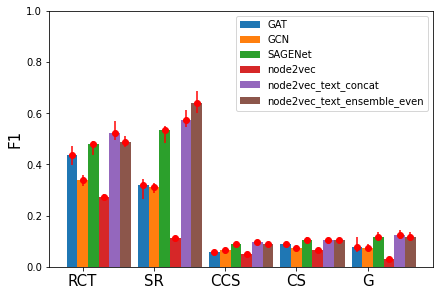

In [333]:
x = np.arange(len(study_design))  # the label locations
width = 0.15  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for attribute, measurement in f1_scores.items():
    offset = width * multiplier
    uquartile = np.array(uncertainty[attribute]['upper'])
    lquartile = np.array(uncertainty[attribute]['lower'])
    errors = [lquartile, uquartile]
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.errorbar(x + offset, measurement, yerr=errors, fmt="o", color="r")
#     ax.bar_label(rects, padding=5)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('F1', fontsize=15)
# ax.set_title('Penguin attributes by species')
ax.set_xticks(x + width, study_design, fontsize=15)
ax.legend(loc='upper right')
ax.set_ylim(0, 1)

plt.show()